# 🛡️ SpamGuard — SMS Spam Detection (production-grade pipeline)
**Everything is saved to your Google Drive**, so a Colab disconnect never loses work:
dataset (downloaded from Kaggle), every trained model (checkpoints), metrics, plots, model registry, feedback, logs.
👉 **If the runtime disconnects, just use *Runtime ▸ Run all* again** — finished models are loaded from Drive and skipped.

### One-time setup (2 minutes)
1. Download **`sms-spam-mlops.zip`** and upload it to the root of **My Drive** (or drag it into Colab's 📁 Files panel).
2. Add your Kaggle credentials as **Colab Secrets** (🔑 icon in the left bar): `KAGGLE_USERNAME` and `KAGGLE_KEY`
   (Kaggle ▸ Settings ▸ API ▸ *Create New Token*). Turn **Notebook access** on for both. No Kaggle account? Set `LOCAL_CSV` below.
3. *Runtime ▸ Run all*. A CPU runtime is enough (GPU not needed). Full benchmark ≈ 10–25 min.

## 1 · Mount Drive & unpack the project

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, glob, shutil, zipfile
PROJECT_DIR = "/content/drive/MyDrive/sms-spam-mlops"      # <- ALL outputs live here (change if you like)
os.makedirs(PROJECT_DIR, exist_ok=True)

if not os.path.exists(f"{PROJECT_DIR}/src/spamguard/train.py"):
    candidates = ["/content/drive/MyDrive/sms-spam-mlops.zip", "/content/sms-spam-mlops.zip"]
    zip_path = next((p for p in candidates if os.path.exists(p)), None)
    if zip_path is None:
        from google.colab import files
        print("Upload sms-spam-mlops.zip ..."); zip_path = "/content/" + list(files.upload())[0]
    tmp = "/content/_unzip"; shutil.rmtree(tmp, ignore_errors=True)
    zipfile.ZipFile(zip_path).extractall(tmp)
    root = tmp if os.path.exists(f"{tmp}/src") else glob.glob(f"{tmp}/*/")[0]
    shutil.copytree(root, PROJECT_DIR, dirs_exist_ok=True)
    print("Project unpacked to", PROJECT_DIR)
else:
    print("Project already on Drive:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Upload sms-spam-mlops.zip ...


Saving sms-spam-mlops.zip to sms-spam-mlops.zip
Project unpacked to /content/drive/MyDrive/sms-spam-mlops


## 2 · Install dependencies

In [3]:
!pip install -q -r {PROJECT_DIR}/requirements.txt
sys.path.insert(0, f"{PROJECT_DIR}/src")
os.environ["PYTHONPATH"] = f"{PROJECT_DIR}/src"
print("✅ dependencies installed (if Colab asks to restart the runtime, restart and Run all again)")

✅ dependencies installed (if Colab asks to restart the runtime, restart and Run all again)


## 3 · Kaggle credentials, dataset choice & settings

In [4]:
# ---------------- settings you may change ----------------
DATASET   = "uci"    # "uci" (recommended benchmark, 5.5k msgs)  |  "multilingual" (~100k rows, 21 languages, see README caveat)
LOCAL_CSV = None     # e.g. "/content/drive/MyDrive/spam.csv" to skip Kaggle entirely
FAST      = False    # True = tiny search budget (3-4 min smoke test)
RESUME    = True     # True = reuse finished checkpoints from Drive
# ----------------------------------------------------------
os.environ["SPAMGUARD_HOME"] = PROJECT_DIR

if LOCAL_CSV is None:
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        print("✅ Kaggle credentials loaded from Colab Secrets")
    except Exception:
        from google.colab import files
        print("No Colab Secrets found - upload your kaggle.json"); files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        shutil.move("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json")); os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

# MLflow's SQLite DB is kept on the fast local disk (Drive's FUSE layer can lock SQLite) and synced to Drive afterwards.
os.environ["MLFLOW_TRACKING_URI"] = "sqlite:////content/mlflow.db"
if os.path.exists(f"{PROJECT_DIR}/mlflow.db") and not os.path.exists("/content/mlflow.db"):
    shutil.copy(f"{PROJECT_DIR}/mlflow.db", "/content/mlflow.db")

No Colab Secrets found - upload your kaggle.json


Saving kaggle.json to kaggle.json


## 4 · Train & benchmark **16 models** (leakage-safe, checkpointed)
Pipeline: clean → de-duplicate → **stratified** train/val/test → per model: random-search CV (PR-AUC) inside a
`Pipeline` (vectoriser fitted only on training folds) → champion chosen on **validation** → probability calibration →
decision threshold tuned on out-of-fold predictions → **one** final test evaluation with bootstrap CIs.
Each model is saved to `Drive/.../checkpoints/` the moment it finishes.

In [5]:
from spamguard.config import load_params
from spamguard.train import run

over = {"data": {"source": "local" if LOCAL_CSV else DATASET, "local_path": LOCAL_CSV}, "training": {"n_jobs": -1}}
params = load_params(overrides=over)
summary = run(params, resume=RESUME, fast=FAST)
shutil.copy("/content/mlflow.db", f"{PROJECT_DIR}/mlflow.db") if os.path.exists("/content/mlflow.db") else None
print("\nChampion:", summary["champion"], "| version:", summary["version"], "| threshold:", round(summary["threshold"], 4))

06:51:41 | INFO    | spamguard.data | Downloading uciml/sms-spam-collection-dataset from Kaggle ...
06:51:44 | INFO    | spamguard.data | Reading spam.csv
06:51:45 | INFO    | spamguard.data | Cleaning report: {'rows_raw': 5572, 'rows_after_cleaning': 5157, 'duplicates_removed': 415, 'conflicting_label_texts_removed': 0, 'spam_rate': 0.1245}
06:51:45 | INFO    | spamguard.data | Splits: {'train': {'rows': 3609, 'spam_rate': 0.1247}, 'val': {'rows': 774, 'spam_rate': 0.124}, 'test': {'rows': 774, 'spam_rate': 0.124}}
06:51:57 | INFO    | spamguard.train | [dummy_prior] cv PR-AUC 0.1247±0.0000 | fit 3.9s | 5.6 ms/msg | 0.2 MB
06:52:16 | INFO    | spamguard.train | [multinomial_nb] cv PR-AUC 0.9811±0.0057 | fit 18.5s | 6.0 ms/msg | 0.6 MB
06:52:34 | INFO    | spamguard.train | [complement_nb] cv PR-AUC 0.9816±0.0061 | fit 17.0s | 5.8 ms/msg | 0.7 MB
06:52:54 | INFO    | spamguard.train | [bernoulli_nb] cv PR-AUC 0.9821±0.0072 | fit 18.4s | 6.4 ms/msg | 0.2 MB
06:53:12 | INFO    | spamguar

2026/11/01 07:03:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/01 07:03:08 INFO mlflow.store.db.utils: Updating database tables
2026/11/01 07:03:10 INFO mlflow.tracking.fluent: Experiment with name 'spamguard' does not exist. Creating a new experiment.
2026/11/01 07:03:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


07:03:17 | INFO    | spamguard.train | Done in 11.4 min. Version 20261101-070302-096c1a promoted=True

Champion: linear_svm | version: 20261101-070302-096c1a | threshold: 0.7776


## 5 · Leaderboard — every model, every metric

In [6]:
import pandas as pd
from IPython.display import display, Image, Markdown
from pathlib import Path
R = Path(PROJECT_DIR) / "reports"; F = R / "figures"
board = pd.read_csv(R / "leaderboard_full.csv")
cols = ["model","family","accuracy","balanced_accuracy","precision","recall","specificity","f1","f2","mcc","cohen_kappa",
        "pr_auc","roc_auc","log_loss","brier","ece","fpr","fnr","tn","fp","fn","tp","threshold","cv_pr_auc","cv_pr_auc_std",
        "latency_ms","size_mb","fit_seconds","f1_at_0.5","mcnemar_p_vs_champion","is_champion"]
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)
display(board[cols].round(4).style.background_gradient(subset=["f1","pr_auc","mcc","roc_auc"], cmap="Greens")
        .background_gradient(subset=["ece","brier","log_loss"], cmap="Reds").highlight_between(subset=["is_champion"], left=1, right=1, color="gold"))

,model,family,accuracy,balanced_accuracy,precision,recall,specificity,f1,f2,mcc,cohen_kappa,pr_auc,roc_auc,log_loss,brier,ece,fpr,fnr,tn,fp,fn,tp,threshold,cv_pr_auc,cv_pr_auc_std,latency_ms,size_mb,fit_seconds,f1_at_0.5,mcnemar_p_vs_champion,is_champion
0,lightgbm,boosting,0.978000,0.911500,1.000000,0.822900,1.000000,0.902900,0.853100,0.896000,0.890600,0.993100,0.998700,0.048800,0.008800,0.010100,0.000000,0.177100,678,0,17,79,0.999000,0.977900,0.003700,33.796000,0.400000,48.090000,0.962600,0.031200,False
1,extra_trees,tree_ensemble,0.976700,0.906200,1.000000,0.812500,1.000000,0.896600,0.844200,0.889700,0.883600,0.992000,0.998800,0.047100,0.010800,0.023700,0.000000,0.187500,678,0,18,78,0.768000,0.979800,0.009100,71.892000,1.970000,24.520000,0.940500,0.015600,False
2,rbf_svm,svm,0.979300,0.916700,1.000000,0.833300,1.000000,0.909100,0.862100,0.902300,0.897500,0.991700,0.997200,0.025500,0.005800,0.009800,0.000000,0.166700,678,0,16,80,0.970700,0.984400,0.003600,7.144000,1.360000,106.750000,0.963400,0.062500,False
3,linear_svm,svm,0.972900,0.890600,1.000000,0.781200,1.000000,0.877200,0.817000,0.870500,0.862200,0.991100,0.997400,0.031100,0.007000,0.011800,0.000000,0.218800,678,0,21,75,0.948100,0.984000,0.004100,7.344000,0.460000,17.610000,0.962600,nan,True
4,voting_soft,ensemble,0.974200,0.895800,1.000000,0.791700,1.000000,0.883700,0.826100,0.876900,0.869400,0.990400,0.997300,0.031100,0.007800,0.009600,0.000000,0.208300,678,0,20,76,0.967700,0.983500,0.004900,8.611000,1.140000,4.710000,0.957900,0.003900,False
5,bernoulli_nb,naive_bayes,0.983200,0.932300,1.000000,0.864600,1.000000,0.927400,0.888700,0.921000,0.917900,0.990400,0.995300,0.084200,0.005400,0.005500,0.000000,0.135400,678,0,13,83,1.000000,0.982100,0.007200,6.371000,0.250000,18.360000,0.978900,0.774400,False
6,random_forest,tree_ensemble,0.962500,0.849000,1.000000,0.697900,1.000000,0.822100,0.742800,0.818100,0.801900,0.989500,0.998500,0.064600,0.014200,0.038700,0.000000,0.302100,678,0,29,67,0.815400,0.975900,0.005000,72.814000,1.040000,26.490000,0.923100,0.000000,False
7,stacking,ensemble,0.974200,0.895800,1.000000,0.791700,1.000000,0.883700,0.826100,0.876900,0.869400,0.989200,0.997000,0.038300,0.008700,0.004300,0.000000,0.208300,678,0,20,76,0.983600,0.982900,0.004700,8.789000,1.140000,8.150000,0.952900,0.003900,False
8,adaboost,tree_ensemble,0.970300,0.880200,1.000000,0.760400,1.000000,0.863900,0.798700,0.857600,0.847600,0.988800,0.997900,0.402600,0.111300,0.312400,0.000000,0.239600,678,0,23,73,0.558900,0.972500,0.004400,31.894000,0.200000,65.510000,0.934100,0.000500,False
9,xgboost,boosting,0.970300,0.880200,1.000000,0.760400,1.000000,0.863900,0.798700,0.857600,0.847600,0.988100,0.997900,0.038900,0.010700,0.008900,0.000000,0.239600,678,0,23,73,0.931500,0.972900,0.004200,6.877000,0.310000,161.380000,0.934100,0.000500,False


leaderboard_bars


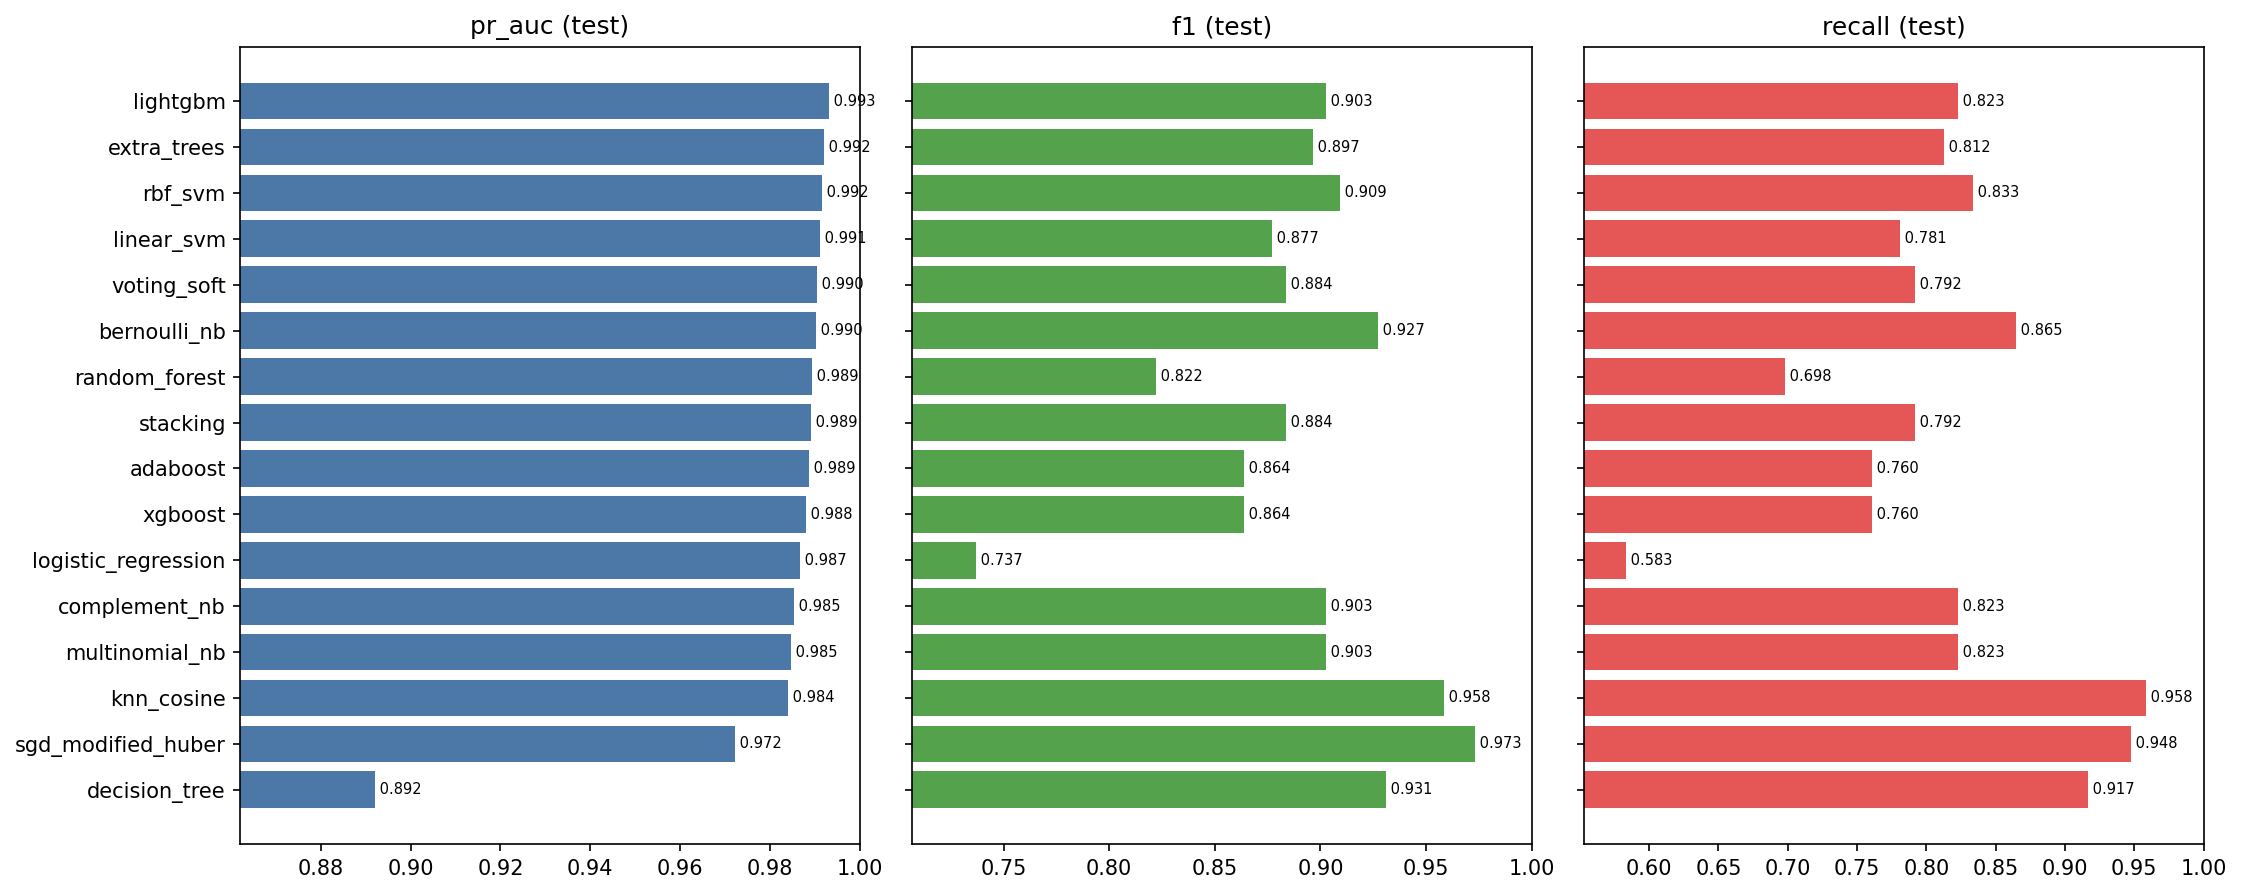

metric_heatmap


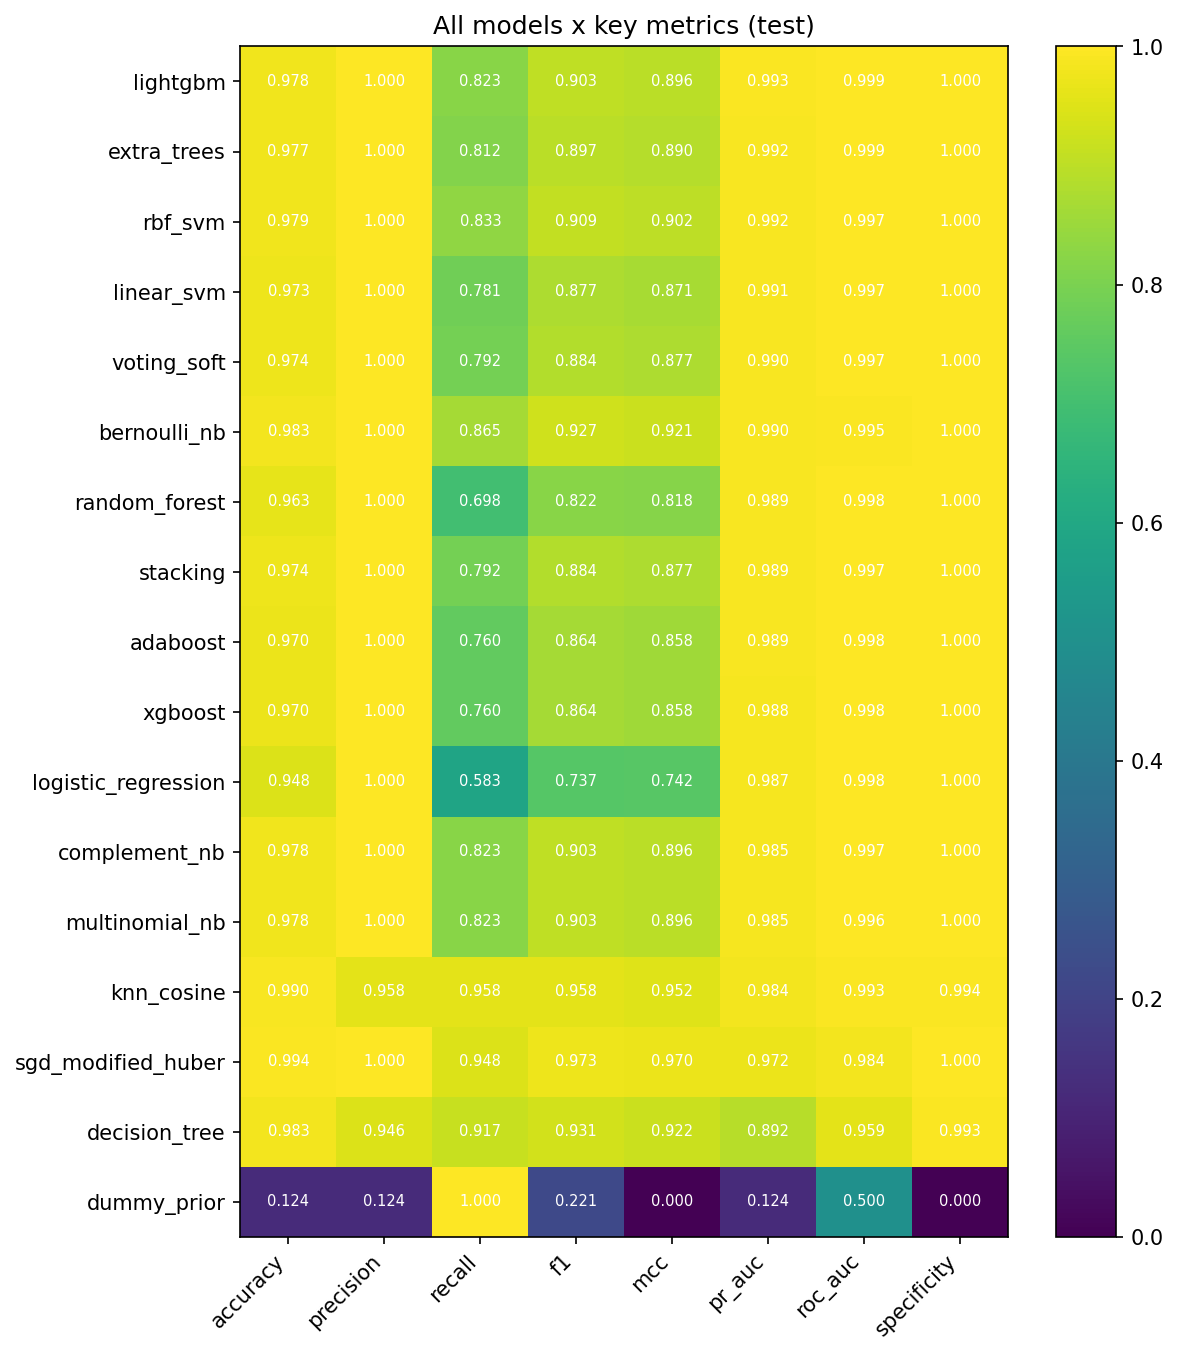

pr_all_models


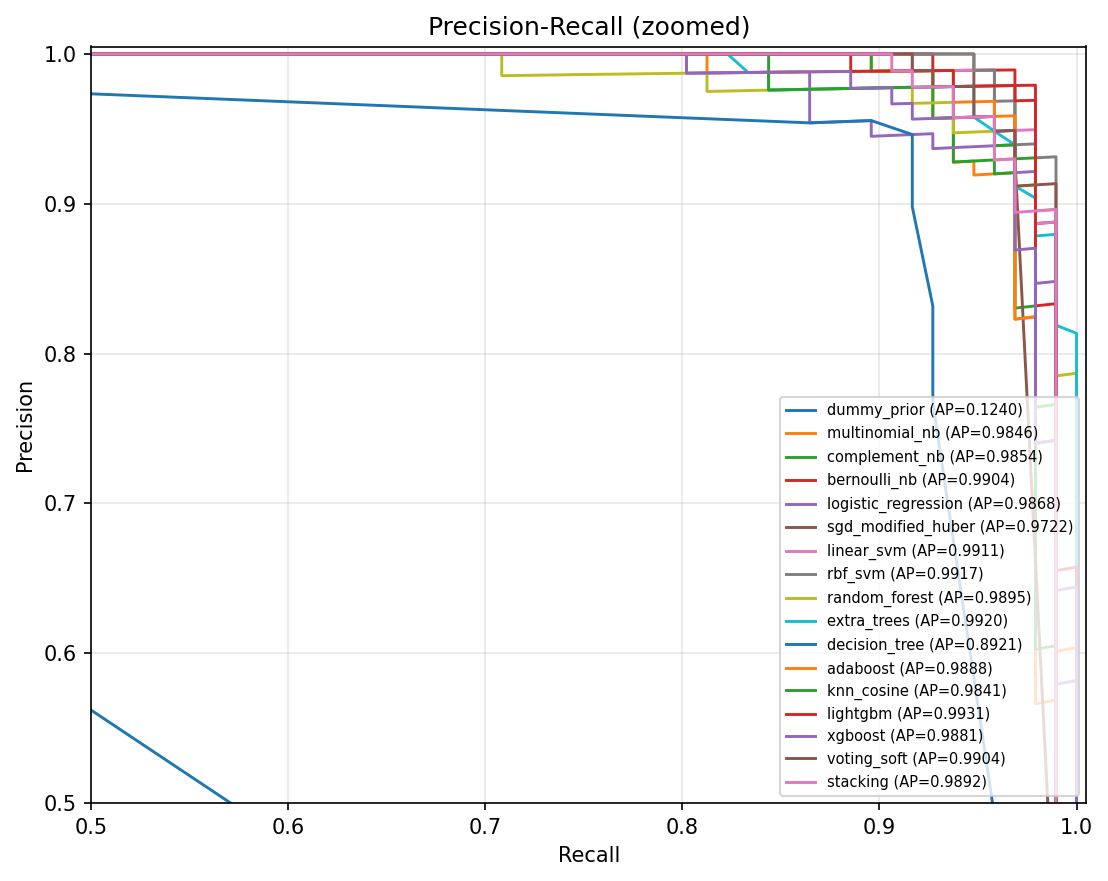

roc_all_models


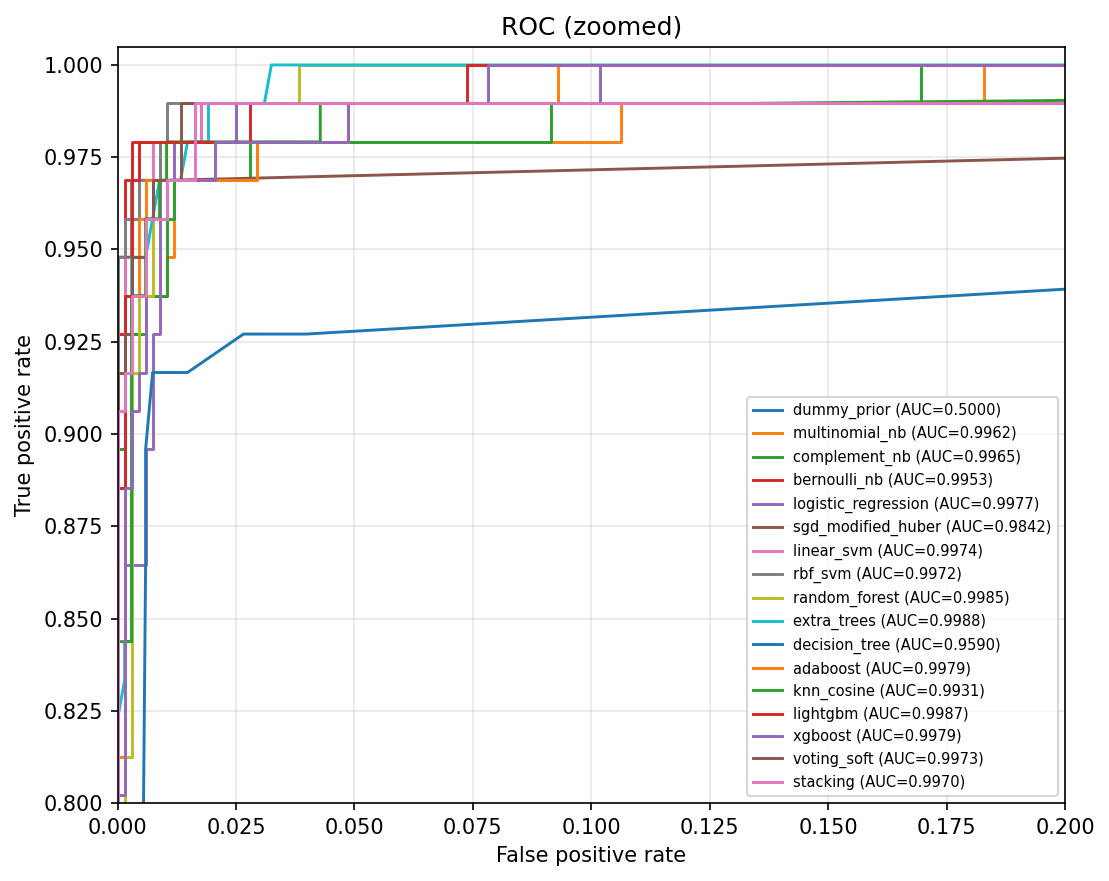

calibration_all_models


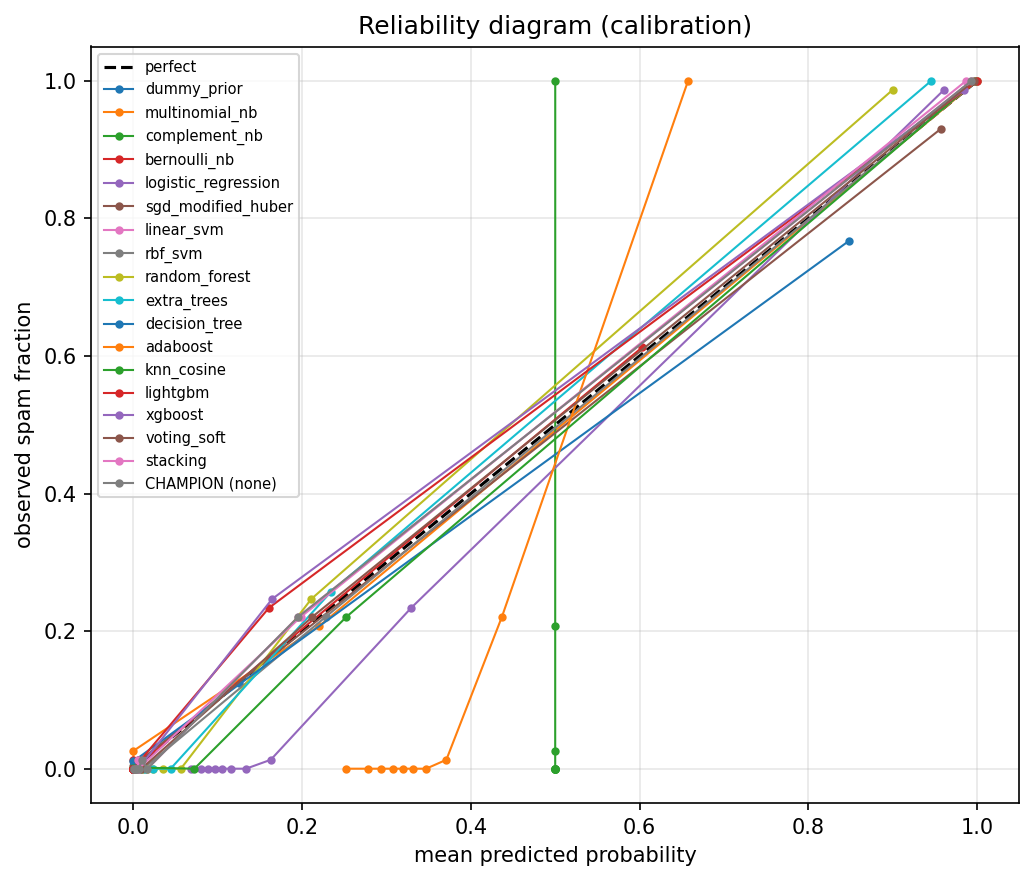

speed_vs_quality


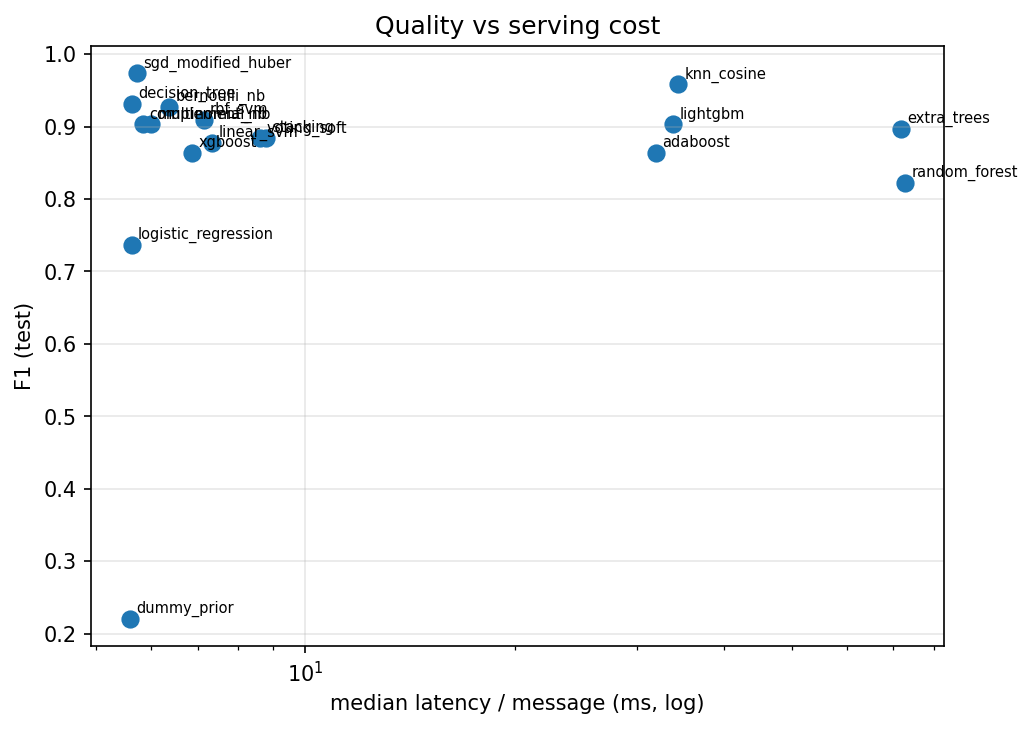

In [7]:
for name in ["leaderboard_bars","metric_heatmap","pr_all_models","roc_all_models","calibration_all_models","speed_vs_quality"]:
    print(name); display(Image(str(F / f"{name}.png"), width=900))

## 6 · Champion deep-dive: CIs, threshold, calibration, confusion matrix, robustness

,value,95% CI low,95% CI high
precision,1.0000,1.0000,1.0000
recall,0.8854,0.8227,0.9479
f1,0.9392,0.9027,0.9733
mcc,0.9334,0.8958,0.9700
pr_auc,0.9911,0.9749,0.9995
roc_auc,0.9974,0.9919,0.9999
fpr,0.0000,0.0000,0.0000


Calibration comparison (validation):


,none,sigmoid,isotonic
val_brier,0.0106,0.0132,0.0094
val_ece,0.0105,0.0067,0.0059
val_log_loss,0.0405,0.0569,0.0775


confusion_champion


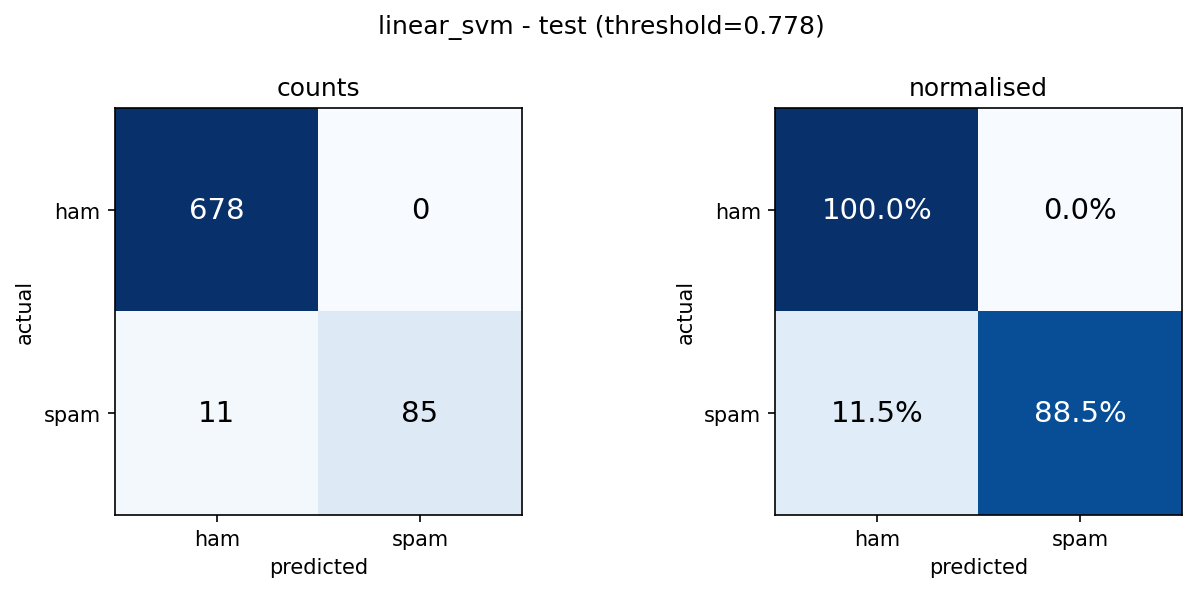

threshold_sweep_champion


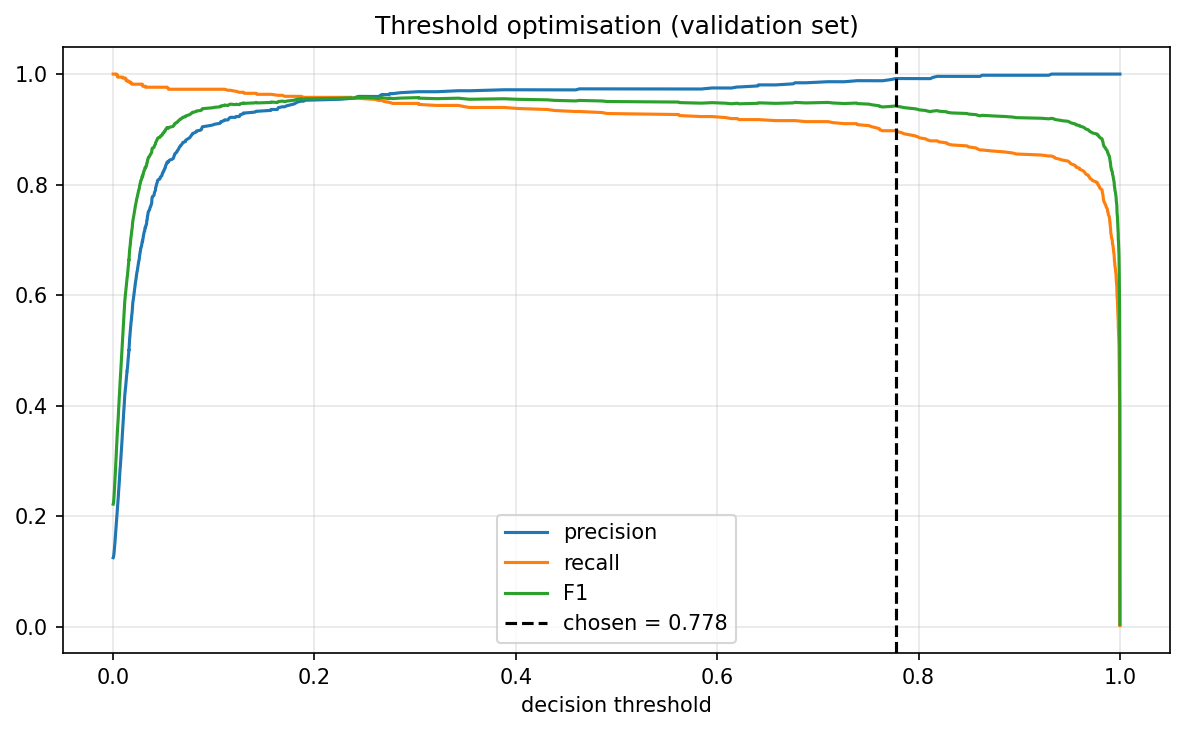

score_distribution_champion


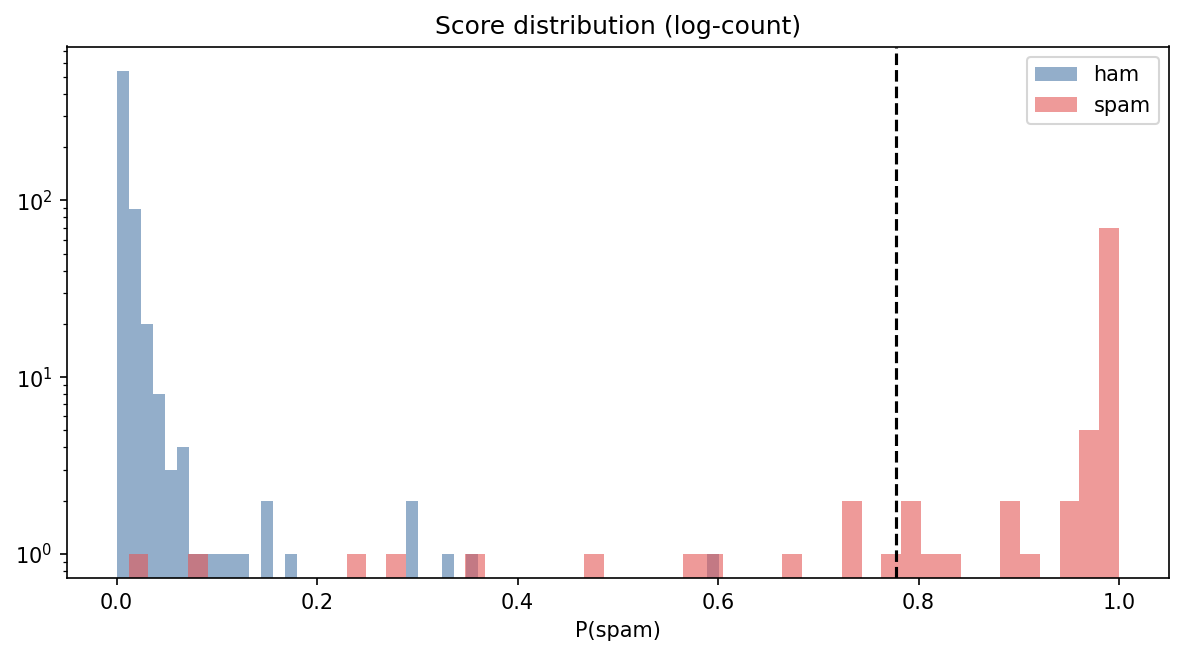

robustness


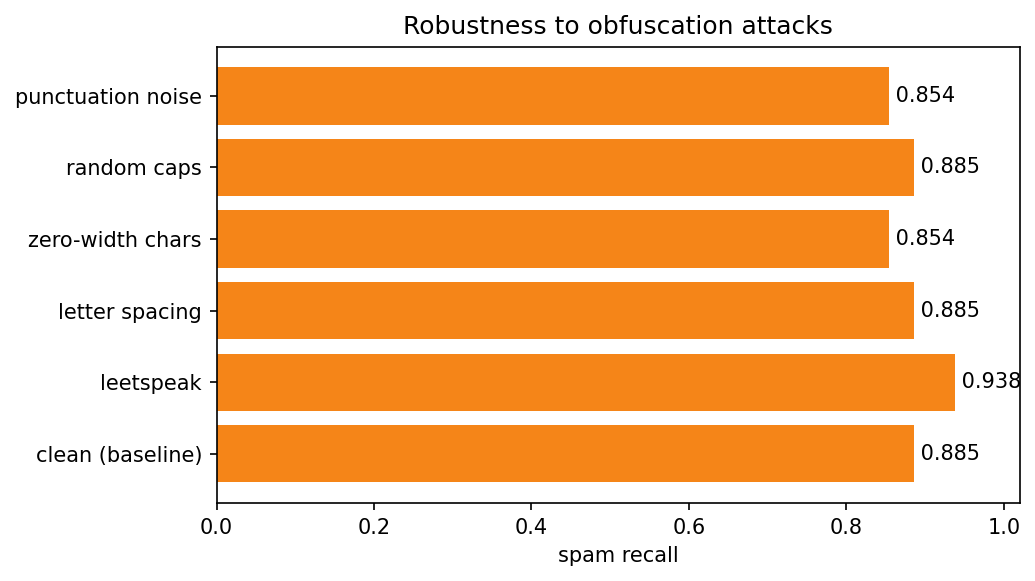

top_features_logreg


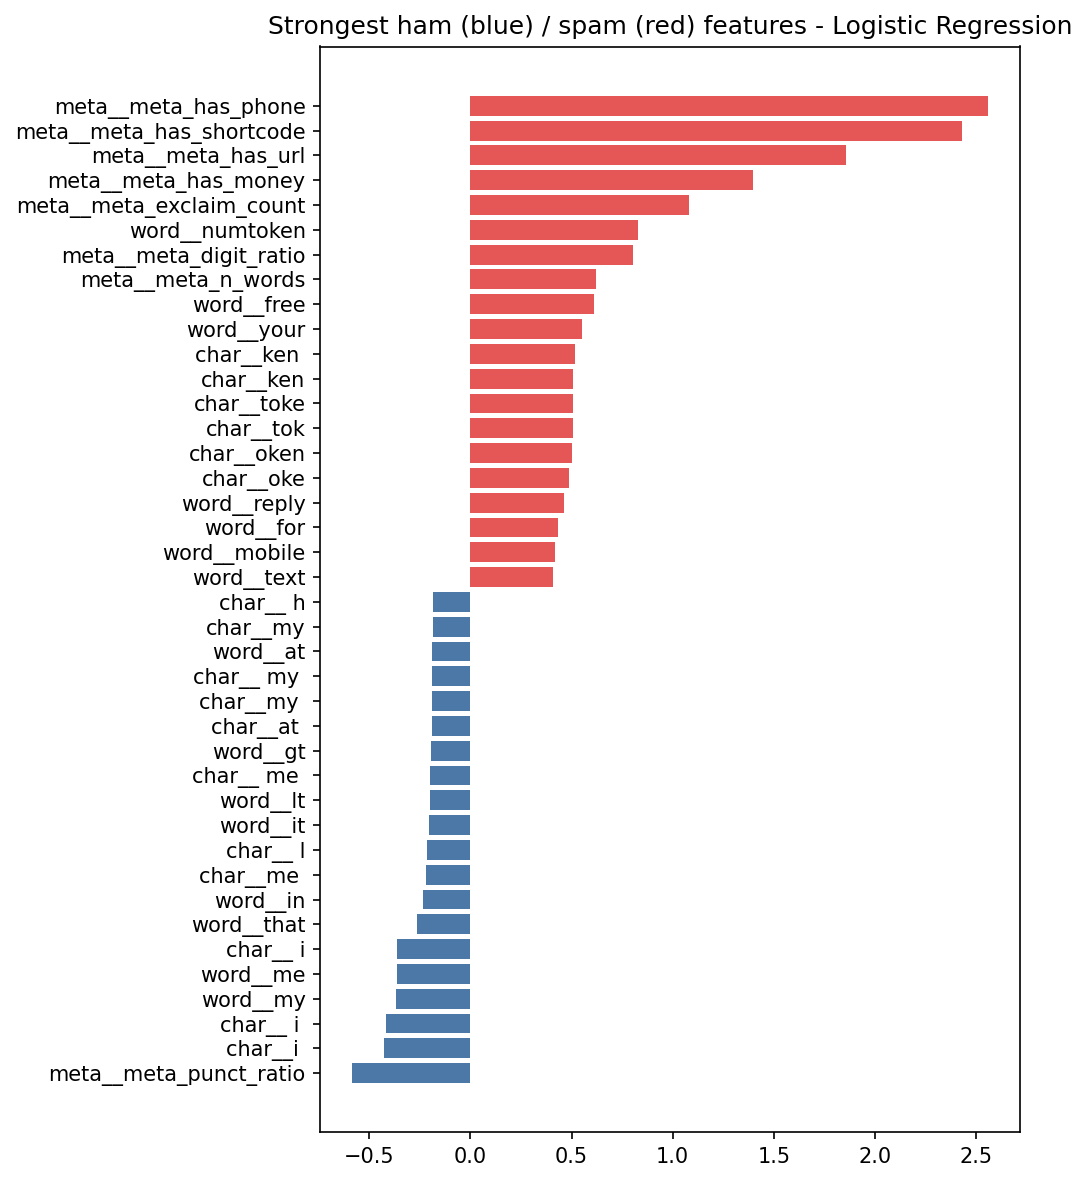

Spam recall under obfuscation attacks:


,attack,spam_recall,mean_spam_score
0,clean (baseline),0.8854,0.9171
1,leetspeak,0.9375,0.9624
2,letter spacing,0.8854,0.9149
3,zero-width chars,0.8542,0.9026
4,random caps,0.8854,0.9183
5,punctuation noise,0.8542,0.8993


Metrics by message length:


,length_bucket,n,spam_rate,precision,recall,f1,fp,fn
0,<=40,218,0.0000,0.0,0.0000,0.0000,0,0
1,41-100,322,0.0217,1.0,0.7143,0.8333,0,2
2,101-160,202,0.4010,1.0,0.8889,0.9412,0,9
3,>160,32,0.2500,1.0,1.0000,1.0000,0,0


In [8]:
import json
s = json.load(open(R / "summary.json"))
ci = s["bootstrap_ci_test"]; m = s["metrics_test"]
display(pd.DataFrame({k: {"value": m[k], "95% CI low": ci[k]["low"], "95% CI high": ci[k]["high"]} for k in ci}).T.round(4))
print("Calibration comparison (validation):"); display(pd.read_json(R / "calibration_comparison.json").round(4))
for name in ["confusion_champion","threshold_sweep_champion","score_distribution_champion","robustness","top_features_logreg"]:
    p = F / f"{name}.png"
    if p.exists(): print(name); display(Image(str(p), width=800))
print("Spam recall under obfuscation attacks:"); display(pd.read_csv(R / "robustness.csv").round(4))
print("Metrics by message length:"); display(pd.read_csv(R / "slice_metrics.csv"))

In [9]:
display(Markdown("### ❌ False positives (legit messages flagged as spam) — the costly error"))
display(pd.read_csv(R / "errors_false_positives.csv").head(10))
display(Markdown("### ❌ False negatives (missed spam)"))
display(pd.read_csv(R / "errors_false_negatives.csv").head(10))
display(Markdown((R / "MODEL_CARD.md").read_text()))

### ❌ False positives (legit messages flagged as spam) — the costly error

,text,label,score,pred


### ❌ False negatives (missed spam)

,text,label,score,pred
0,"Hi this is Amy, we will be sending you a free ...",1,0.012017,0
1,"SMS. ac JSco: Energy is high, but u may not kn...",1,0.088613,0
2,Babe: U want me dont u baby! Im nasty and have...,1,0.245188,0
3,Sorry! U can not unsubscribe yet. THE MOB offe...,1,0.273340,0
4,(Bank of Granite issues Strong-Buy) EXPLOSIVE ...,1,0.357843,0
5,Sorry I missed your call let's talk when you h...,1,0.483100,0
6,TheMob>Yo yo yo-Here comes a new selection of ...,1,0.580901,0
7,Welcome! Please reply with your AGE and GENDER...,1,0.585517,0
8,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,1,0.677908,0
9,"FreeMsg Hey U, i just got 1 of these video/pic...",1,0.730018,0


# Model card - SpamGuard `20261101-070302-096c1a`

**Task:** binary classification of SMS messages (spam vs ham). **Champion:** `linear_svm`
(calibration: `none`), 17 models compared.

## Data
Source `uci`; 5157 messages after cleaning (415 duplicates and
0 label-conflicts removed); spam rate 12.4%.
Stratified split: {"train": {"rows": 3609, "spam_rate": 0.1247}, "val": {"rows": 774, "spam_rate": 0.124}, "test": {"rows": 774, "spam_rate": 0.124}}.

## Decision policy
Threshold **0.7776** chosen (5-fold OOF on train+val (n=4383)) with strategy `min_precision`
(max recall subject to precision >= 0.99). Blocking a legitimate message is treated as costlier than missing spam.

## Test performance (held out, used once)
| metric | value |
|---|---|
| Precision | 1.0000 (95% CI 1.0000-1.0000) |
| Recall | 0.8854 (95% CI 0.8227-0.9479) |
| F1 | 0.9392 (95% CI 0.9027-0.9733) |
| MCC | 0.9334 (95% CI 0.8958-0.9700) |
| PR-AUC | 0.9911 (95% CI 0.9749-0.9995) |
| ROC-AUC | 0.9974 (95% CI 0.9919-0.9999) |
| False-positive rate | 0.0000 (95% CI 0.0000-0.0000) |
| Brier / ECE | 0.0070 / 0.0118 |
| Confusion (TN/FP/FN/TP) | 678/0/11/85 |

### Top 5 models
| model       |   precision |   recall |     f1 |   pr_auc |   roc_auc |    mcc |
|:------------|------------:|---------:|-------:|---------:|----------:|-------:|
| lightgbm    |           1 |   0.8229 | 0.9029 |   0.9931 |    0.9987 | 0.896  |
| extra_trees |           1 |   0.8125 | 0.8966 |   0.992  |    0.9988 | 0.8897 |
| rbf_svm     |           1 |   0.8333 | 0.9091 |   0.9917 |    0.9972 | 0.9023 |
| linear_svm  |           1 |   0.7812 | 0.8772 |   0.9911 |    0.9974 | 0.8705 |
| voting_soft |           1 |   0.7917 | 0.8837 |   0.9904 |    0.9973 | 0.8769 |

### Robustness (spam recall under evasion attacks)
| attack            |   spam_recall |   mean_spam_score |
|:------------------|--------------:|------------------:|
| clean (baseline)  |         0.885 |             0.917 |
| leetspeak         |         0.938 |             0.962 |
| letter spacing    |         0.885 |             0.915 |
| zero-width chars  |         0.854 |             0.903 |
| random caps       |         0.885 |             0.918 |
| punctuation noise |         0.854 |             0.899 |

## Limitations & ethical notes
* Trained on English SMS (2000s UK/Singapore-era corpus): new scams (crypto, delivery, bank-OTP phishing) and other
  languages are likely under-represented -> monitor drift and collect feedback.
* The test set is small; differences between the top models are usually inside the confidence interval.
* Messages are personal data: prediction logs store hashes + numeric features, never raw text by default.
* A spam flag should trigger *soft* actions (move to junk folder) rather than silent deletion.


## 7 · Try it: predictions + word-level explanations

In [10]:
from spamguard.predictor import Predictor
pred = Predictor.from_champion()
tests = ["URGENT! Your parcel is held. Pay the $2.99 customs fee at http://dhl-track.xyz/pay today",
         "Hey, are we still on for dinner at 8?",
         "WINNER!! You have been selected for a £900 prize. Call 09061701461 now"]
for t in tests:
    r = pred.predict([t], explain=True)[0]
    ex = r["explanation"]
    print(f"{r['label'].upper():5s} P(spam)={r['spam_probability']:.3f} | {t[:70]}")
    print("      pushes → spam:", [(x['token'], round(x['weight'], 2)) for x in ex['top_spam_tokens'][:4]],
          "| → ham:", [(x['token'], round(x['weight'], 2)) for x in ex['top_ham_tokens'][:3]])

SPAM  P(spam)=0.929 | URGENT! Your parcel is held. Pay the $2.99 customs fee at http://dhl-t
      pushes → spam: [('http://dhl-track.xyz/pay', 3.01), ('$2.99', 2.1), ('URGENT!', 0.56), ('Your', 0.41)] | → ham: [('at', -0.44), ('is', -0.16), ('Pay', -0.05)]
HAM   P(spam)=0.008 | Hey, are we still on for dinner at 8?
      pushes → spam: [('8?', 1.01), ('for', 0.45), ('are', 0.26), ('on', 0.12)] | → ham: [('at', -0.61), ('we', -0.3), ('still', -0.18)]
SPAM  P(spam)=0.999 | WINNER!! You have been selected for a £900 prize. Call 09061701461 now
      pushes → spam: [('09061701461', 5.17), ('£900', 1.81), ('WINNER!!', 0.78), ('for', 0.36)] | → ham: [('have', -0.08), ('been', -0.07)]


## 8 · Monitoring demo: data drift
Normal traffic should be `ok`; a brand-new scam campaign should trigger an `alert` (PSI + KS tests on message features, OOV rate and score
distribution). An **Evidently** HTML report is also written to `reports/drift_report.html`.

In [11]:
from spamguard.monitoring import run_check
logp = Path(PROJECT_DIR) / "logs" / "predictions.jsonl"
test_df = pd.read_csv(Path(PROJECT_DIR) / "data/processed/test.csv")
if logp.exists(): logp.unlink()
pred.predict(test_df["text"].tolist()[:300]);  print("normal traffic →", run_check()["status"])
logp.unlink()
pred.predict([f"Your parcel {i} is held. Pay customs fee $2.99 at https://dhl-track{i}.xyz/pay today, bitcoin accepted URGENT" for i in range(300)])
rep = run_check(); print("new scam wave →", rep["status"], "| drifted:", rep["drifted_features"][:6])
logp.unlink()

07:03:24 | INFO    | spamguard.monitoring | Drift status: ok ([])
normal traffic → ok
07:03:25 | INFO    | spamguard.monitoring | Drift status: alert (['n_chars', 'n_words', 'digit_ratio', 'upper_ratio', 'punct_ratio', 'exclaim_count', 'has_url', 'has_phone', 'has_money', 'has_shortcode', 'oov_rate', 'score'])
new scam wave → alert | drifted: ['n_chars', 'n_words', 'digit_ratio', 'upper_ratio', 'punct_ratio', 'exclaim_count']


## 9 · Human feedback loop + champion/challenger retraining demo

In [12]:
from spamguard.retrain import retrain
# NOTE: demo rows are tagged source='demo'. Delete Drive/.../data/feedback/feedback.jsonl before real use.
# simulate analysts correcting the model (in production this comes from the /feedback API or the Gradio buttons)
fn = pd.read_csv(R / "errors_false_negatives.csv")["text"].tolist()
extra_spam = [f"URGENT! Verify your account now at http://secure-login{i}.xyz or it will be suspended" for i in range(30)]
for t in fn + extra_spam:  pred.record_feedback(t, "spam", source="demo")
for t in ["ok see you soon", "can you send me the notes?", "running late, start without me"] * 8: pred.record_feedback(t + f" ({hash(t) % 97})", "ham", source="demo")
res = retrain(promote=False, force=True)       # promote=True would register the challenger if it passes the gate
print(json.dumps(res, indent=2))

07:03:26 | INFO    | spamguard.retrain | Retraining on 3609 base + 33 feedback rows
07:03:35 | INFO    | spamguard.retrain | Retrain result: {"status": "evaluated", "feedback_rows_used": 33, "passes_gate": true, "champion": {"precision": 1.0, "recall": 0.8854, "f1": 0.9392, "pr_auc": 0.9911, "fpr": 0.0, "version": "20261101-070302-096c1a"}, "challenger": {"precision": 1.0, "recall": 0.8438, "f1": 0.9153, "pr_auc": 0.9916, "fpr": 0.0}, "promoted": false}
{
  "status": "evaluated",
  "feedback_rows_used": 33,
  "passes_gate": true,
  "champion": {
    "precision": 1.0,
    "recall": 0.8854,
    "f1": 0.9392,
    "pr_auc": 0.9911,
    "fpr": 0.0,
    "version": "20261101-070302-096c1a"
  },
  "challenger": {
    "precision": 1.0,
    "recall": 0.8438,
    "f1": 0.9153,
    "pr_auc": 0.9916,
    "fpr": 0.0
  },
  "promoted": false
}


## 10 · Launch the app
* **Gradio UI** (public share link, works from your phone): classify + highlighted explanation, feedback buttons, CSV batch scoring, model dashboard, drift monitor.
* **FastAPI** service running in the background on port 8000 (`/docs` has the Swagger UI inside the project; here we call it with `requests`).

In [13]:
import threading, time, requests, uvicorn
from spamguard.api import create_app
server = uvicorn.Server(uvicorn.Config(create_app(enable_ui=False), host="127.0.0.1", port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start(); time.sleep(4)
print(requests.get("http://127.0.0.1:8000/model-info").json())
print(requests.post("http://127.0.0.1:8000/predict", json={"text": "Free entry! Text WIN to 80086 to claim your prize", "explain": False}).json())

07:03:39 | INFO    | spamguard.api | Loaded champion model 20261101-070302-096c1a
{'version': '20261101-070302-096c1a', 'model': 'linear_svm', 'calibration': 'none', 'threshold': 0.7775661797341527, 'created_utc': '2026-11-01T07:03:03.124354+00:00', 'sha256': '83208d9ecce47413f585145be5a9be794cdcf8dc92f487803659d03ac3640509', 'metrics_test': {'precision': 1.0, 'recall': 0.8854166666666666, 'f1': 0.9392265193370166, 'pr_auc': 0.9911215200444903, 'roc_auc': 0.9974342428711898, 'mcc': 0.9334242560592207}, 'data_fingerprint': '096c1a8a37527d70'}
{'prediction_id': 'af82c39fba8b', 'label': 'spam', 'spam_probability': 0.995903, 'threshold': 0.777566, 'model_version': '20261101-070302-096c1a', 'latency_ms': 9.313}


In [14]:
from spamguard.app_gradio import build_ui
demo = build_ui(lambda: pred)
demo.launch(share=True, debug=False)      # <- click the public gradio.live link

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a0b88ef6dc921efd74.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11 · (Optional) Run the automated test-suite & package results for download

In [ ]:
!cd {PROJECT_DIR} && pip install -q pytest httpx && python -m pytest -q -x 2>&1 | tail -5

In [16]:
import shutil, json
champ = json.load(open(f"{PROJECT_DIR}/models/champion.json"))["version"]
out = f"{PROJECT_DIR}/exports"; os.makedirs(out, exist_ok=True)
tmp = "/content/_export"; shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(f"{PROJECT_DIR}/reports", f"{tmp}/reports")
shutil.copytree(f"{PROJECT_DIR}/models/versions/{champ}", f"{tmp}/models/versions/{champ}")
shutil.copy(f"{PROJECT_DIR}/models/champion.json", f"{tmp}/models/champion.json")
shutil.copy(f"{PROJECT_DIR}/models/registry.json", f"{tmp}/models/registry.json")
archive = shutil.make_archive(f"{out}/spamguard_results_{champ}", "zip", tmp)
print("📦 saved to Drive:", archive)
from google.colab import files; files.download(archive)     # <- uncomment to download straight to your computer

📦 saved to Drive: /content/drive/MyDrive/sms-spam-mlops/exports/spamguard_results_20261101-070302-096c1a.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What's saved in `My Drive/sms-spam-mlops/`
| Folder | Contents |
|---|---|
| `data/raw`, `data/processed` | Kaggle download (cached) · cleaned train/val/test CSVs + manifest (data fingerprint) |
| `checkpoints/` | one `.joblib/.json/.npz` per model → **resume after disconnect** |
| `models/` | versioned, checksummed model registry + `champion.json` (promote / rollback) |
| `reports/` | leaderboard (CSV+MD), metrics.json, model card, error analysis, drift reference, **all figures** |
| `data/feedback`, `logs/` | human feedback · privacy-safe prediction logs |
| `mlflow.db`, `exports/` | experiment tracking · zipped results for download |

**Next:** copy the project to GitHub (CI is pre-configured), `docker compose up --build` to serve it, `dvc init` for data/model versioning.